In [1]:
! pip install -q optuna
! pip install -q emoji
! pip install -q iterative-stratification

In [2]:
import pandas as pd
import numpy as np
import tqdm
from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict
from huggingface_hub import login
import torch
from torch import nn
import torch.nn.functional as F
from sklearn.utils.class_weight import compute_class_weight
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
import optuna
import ast
import re
import emoji
from transformers.utils import logging as hf_logging
import gc
import shutil
import random
import math
import html
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, Trainer, TrainingArguments, AutoModelForSequenceClassification, EarlyStoppingCallback, TrainerCallback, set_seed
from scipy.special import softmax
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score, classification_report
import datasets
import optuna
import sys
from sklearn.metrics import confusion_matrix
from huggingface_hub.utils import disable_progress_bars
from transformers.trainer_callback import PrinterCallback, ProgressCallback
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()          # laporan load model, warning transformers
hf_logging.disable_progress_bar()         # "Writing model shards", "Loading weights"
disable_progress_bars()                   # progress bar download dari Hugging Face Hub
datasets.disable_progress_bars()          # progress bar "Map"
optuna.logging.set_verbosity(optuna.logging.WARNING)   # log bawaan Optuna per trial

In [3]:
df = pd.read_csv(r'/kaggle/input/datasets/evelynuntariady/thesis/data_thesis_full.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27833 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     27833 non-null  int64 
 1   text_id                        27833 non-null  object
 2   annotators_id                  27833 non-null  object
 3   text                           27832 non-null  object
 4   topic                          27833 non-null  object
 5   is_noise_or_spam_text          27833 non-null  object
 6   toxicity                       27833 non-null  object
 7   polarized                      27833 non-null  object
 8   profanity_obscenity            27833 non-null  object
 9   threat_incitement_to_violence  27833 non-null  object
 10  insults                        27833 non-null  object
 11  identity_attack                27833 non-null  object
 12  sexually_explicit              27833 non-null  object
 13  k

In [5]:
df.isnull().sum()

Unnamed: 0                       0
text_id                          0
annotators_id                    0
text                             1
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
key                              0
cleaned_text                     1
dtype: int64

In [6]:
df_main = df.copy()

In [7]:
cols = [
'is_noise_or_spam_text',
'toxicity',
'polarized',
'profanity_obscenity',
'threat_incitement_to_violence',
'insults',
'identity_attack',
'sexually_explicit'
]

for col in cols:
    df_main[col] = df_main[col].apply(lambda x: ast.literal_eval(x) if isinstance(x,str) else x)

In [8]:
print(cols)
cols2 = cols
cols2.remove('polarized')
print(cols2)

['is_noise_or_spam_text', 'toxicity', 'polarized', 'profanity_obscenity', 'threat_incitement_to_violence', 'insults', 'identity_attack', 'sexually_explicit']
['is_noise_or_spam_text', 'toxicity', 'profanity_obscenity', 'threat_incitement_to_violence', 'insults', 'identity_attack', 'sexually_explicit']


In [9]:
def majority_vote(x):
    x = [int(i) for i in x]
    return round(sum(x)/len(x))

for col in cols2:
    df_main[col] = df_main[col].apply(majority_vote)

In [10]:
df_main = df_main[df_main['is_noise_or_spam_text'] == 0]
df_main = df_main.dropna()
df_main.isnull().sum()

Unnamed: 0                       0
text_id                          0
annotators_id                    0
text                             0
topic                            0
is_noise_or_spam_text            0
toxicity                         0
polarized                        0
profanity_obscenity              0
threat_incitement_to_violence    0
insults                          0
identity_attack                  0
sexually_explicit                0
key                              0
cleaned_text                     0
dtype: int64

In [11]:
df_main.info()

<class 'pandas.core.frame.DataFrame'>
Index: 26379 entries, 0 to 27832
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   Unnamed: 0                     26379 non-null  int64 
 1   text_id                        26379 non-null  object
 2   annotators_id                  26379 non-null  object
 3   text                           26379 non-null  object
 4   topic                          26379 non-null  object
 5   is_noise_or_spam_text          26379 non-null  int64 
 6   toxicity                       26379 non-null  int64 
 7   polarized                      26379 non-null  object
 8   profanity_obscenity            26379 non-null  int64 
 9   threat_incitement_to_violence  26379 non-null  int64 
 10  insults                        26379 non-null  int64 
 11  identity_attack                26379 non-null  int64 
 12  sexually_explicit              26379 non-null  int64 
 13  key   

In [12]:
x = df_main["polarized"].iloc[0]
print(type(x), repr(x))

<class 'list'> ['0', '0']


# Calculate Pol Avg

In [13]:
df_main["polarization_list"] = df_main["polarized"].apply(lambda xs: [int(v) for v in xs])
df_main["pol_avg"] = df_main["polarization_list"].apply(lambda xs: float(np.mean(xs)))

print(df_main[["polarized", "pol_avg"]].head())

   polarized   pol_avg
0     [0, 0]  0.000000
1     [1, 1]  1.000000
2  [0, 0, 0]  0.000000
3  [1, 0, 0]  0.333333
4     [1, 1]  1.000000


# Text Cleaning

In [14]:
SOURCE_COL = "cleaned_text"

for c in [SOURCE_COL]:
    if c in df.columns:
        n = df[c].fillna("").astype(str).map(emoji.emoji_count).gt(0).sum()
        print(f"{c:13s}: {n if n > 0 else 'None'}")

cleaned_text : 5435


In [15]:
import sys
sys.path.append("/kaggle/input/datasets/evelynuntariady/thesis")

from preprocess import preprocess_text

In [16]:
from tqdm import tqdm
tqdm.pandas()

df_main["processed_text"] = (
    df_main[SOURCE_COL]
    .fillna("")
    .astype(str)
    .progress_apply(
        lambda x: preprocess_text(x)
    )
)

pd.set_option("display.max_colwidth", 150)
df_main[[SOURCE_COL, "processed_text"]].sample(10, random_state=42)

100%|██████████| 26379/26379 [00:06<00:00, 3836.95it/s]


,cleaned_text,processed_text
10146,INFO BOGOR: Pemakaman Tionghoa di Jonggol disegel akibat tak mengantongi izin. Foto: Penyegelan dilakukan oleh petugas Satpol PP di areal pemakama...,info bogor pemakaman tionghoa di jonggol disegel akibat tak mengantongi izin. foto penyegelan dilakukan oleh petugas satpol pp di areal pemakaman ...
454,Berikut ini adalah daftar pemain/pasangan yang WDN dari Victor China Open 2023!,berikut ini adalah daftar pemain pasangan yang wdn dari victor china open !
5488,"Saya coba terjemahkan: ""Jika ada orang berkata bahwa Thoriqoh Alawiyah tidak ada baiat, maka pembohonglah orang yang bilang begitu! Sesungguhnya T...","saya coba terjemahkan jika ada orang berkata bahwa thoriqoh alawiyah tidak ada baiat, maka pembohonglah orang yang bilang begitu! sesungguhnya tho..."
9465,"India, Pakistan, China tetap pasar potensial sawit RI","india, pakistan, china tetap pasar potensial sawit ri"
11901,"Mahfud MD dan kuburan China. Dengan segala kontroversinya, saya masih respek pada Prof. @mohmahfudmd, sosok yang ketika di Jogja dulu punya kebias...","mahfud md dan kuburan china. dengan segala kontroversinya, saya masih respek pada prof. , sosok yang ketika di jogja dulu punya kebiasaan belajar ..."
9082,Hamas cuma organisasi kecil dengan peralatan yang terbatas bisa melawan Israel yang dikasih senjata teknologi tinggi. Nih pemimpin-pemimpin negeri...,hamas cuma organisasi kecil dengan peralatan yang terbatas bisa melawan israel yang dikasih senjata teknologi tinggi. nih pemimpin pemimpin negeri...
12599,Pasukan pendudukan Israel menembakkan bom gas ke rumah-rumah warga Palestina selama serangan militer di kamp pengungsi Qalandia di #Jerusalem yang...,pasukan pendudukan israel menembakkan bom gas ke rumah rumah warga palestina selama serangan militer di kamp pengungsi qalandia di jerusalem yang ...
2918,"Termasuk rekor baru Shin Tae-yong, berikut 5 fakta menarik setelah Indonesia U-23 gunduli Chinese Taipei.","termasuk rekor baru shin tae yong, berikut fakta menarik setelah indonesia u gunduli chinese taipei."
19312,"Hasil pengeluaran Pasaran China hari Selasa, 14 November 2023. Prize 1️⃣: 2489, Prize 2️⃣: 4770, Prize 3️⃣: 5103. Shio: BABI. Selamat kepada para ...","hasil pengeluaran pasaran china hari selasa, november . prize keycap , prize keycap , prize keycap . shio babi. selamat kepada para pemenang jackp..."
19595,Israel sebar video propaganda anti-Palestina lewat game anak-anak Angry Birds? Lotta Backlund buka suara,israel sebar video propaganda anti palestina lewat game anak anak angry birds? lotta backlund buka suara


# Balancing 1/3

In [17]:
pos = df_main[df_main["toxicity"] == 1]
neg = df_main[df_main["toxicity"] == 0].sample(n=3 * len(pos), random_state=42)
df_final = pd.concat([pos, neg]).sample(frac=1, random_state=42).reset_index(drop=True)

In [18]:
df_final['toxicity'].value_counts()

toxicity
0    7197
1    2399
Name: count, dtype: int64

# Stage 1

In [19]:
x = df_final[["processed_text", "pol_avg"]]
y = df_final['toxicity']

In [20]:
x_train_full, x_test, y_train_full, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.125, stratify=y_train_full, random_state=42
)

print("Stage 1 split sizes:", {"train": len(x_train), "val": len(x_val), "test": len(x_test)})

Stage 1 split sizes: {'train': 6716, 'val': 960, 'test': 1920}


In [21]:
class_weights_s1 = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weights_s1 = torch.tensor(class_weights_s1, dtype=torch.float)
print("Stage 1 class weights (class 0, class 1):", class_weights_s1)

Stage 1 class weights (class 0, class 1): tensor([0.6667, 2.0000])


In [22]:
def make_df(x, y):
    df = x.copy()
    df["label"] = y.values
    return df.reset_index(drop=True)

train_df = make_df(x_train, y_train)
val_df = make_df(x_val, y_val)
test_df = make_df(x_test, y_test)

dataset = DatasetDict({
    "train": Dataset.from_pandas(train_df),
    "validation": Dataset.from_pandas(val_df),
    "test": Dataset.from_pandas(test_df),
})
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 6716
    })
    validation: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 960
    })
    test: Dataset({
        features: ['processed_text', 'pol_avg', 'label'],
        num_rows: 1920
    })
})


In [23]:
tokenizer = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

In [24]:
def tokenize_with_feature(batch):
    prefix = [f"Nilai rata-rata polarisasi: {v:.2f}" for v in batch["pol_avg"]]
    return tokenizer(prefix, batch["processed_text"], truncation="only_second", max_length=128, padding='max_length')

tokenized = dataset.map(tokenize_with_feature, batched=True)
tokenized = tokenized.remove_columns(["processed_text", "pol_avg"])

print(tokenizer.decode(tokenized["train"][0]["input_ids"]))

[CLS] nilai rata - rata polarisasi : 0. 00 [SEP] kedatangan para martir tak dikenal, anak anak dan wanita yang terluka dalam pemboman pesawat penjajah zionis israel di lingkungan perumahan di al zawaida, jalur gaza tengah. gazagenocides [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [25]:
tokenized_datasets_1 = dataset.map(tokenize_with_feature, batched=True)

tokenized_datasets_1 = tokenized_datasets_1.remove_columns(["processed_text",'pol_avg'])
tokenized_datasets_1 = tokenized_datasets_1.rename_column("label", "labels")
tokenized_datasets_1.set_format("torch")

train_dataset_1 = tokenized_datasets_1["train"]
val_dataset_1 = tokenized_datasets_1["validation"]
test_dataset_1 = tokenized_datasets_1["test"]

In [64]:
print(test_dataset_1)

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 1920
})


In [26]:
def compute_metrics_s1(eval_pred):
    logits, labels = eval_pred
    probs = softmax(logits, axis=1)[:, 1]
    preds = logits.argmax(axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, zero_division=0),
        "recall": recall_score(labels, preds, zero_division=0),
        "f1": f1_score(labels, preds, zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(labels, probs),
        "pr_auc": average_precision_score(labels, probs),
    }

In [27]:
# Trainer that applies class weights to CrossEntropyLoss, used to handle label
# imbalance in Stage 1.
class WeightedTrainerSingleLabel(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        weight = self.class_weights.to(logits.device) if self.class_weights is not None else None
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        # logits.size(-1) instead of model.config.num_labels: stays correct even if
        # Trainer wraps the model in nn.DataParallel (which doesn't expose .config).
        loss = loss_fct(logits.view(-1, logits.size(-1)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

In [28]:
MODEL_NAME = "indolem/indobertweet-base-uncased"
STUDY_NAME = "stage1_balance_polarized_v1"
N_TRIALS = 10
OUTPUT_ROOT = "./optuna_s1"
FINAL_DIR = "./best_s1_optuna"
SEED = 42
LOGGING_STEPS = 10

In [29]:
# search space
def suggest_params(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        "class_weight_alpha": trial.suggest_float("class_weight_alpha", 0.3, 1.0),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }

In [30]:
def freeze_layer(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def build_trainer(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2,
        id2label={0: "non_toxic", 1: "toxic"},
        label2id={"non_toxic": 0, "toxic": 1},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])

    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_1) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        weight_decay=params["weight_decay"],
        lr_scheduler_type=params["lr_scheduler_type"],
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model="f1",
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric="eval_f1"))

    return WeightedTrainerSingleLabel(
        model=model,
        args=args,
        train_dataset=train_dataset_1,
        eval_dataset=val_dataset_1,
        compute_metrics=compute_metrics_s1,
        class_weights=class_weights_s1 ** params["class_weight_alpha"],   # alpha=1 -> balanced penuh
        callbacks=callbacks,
    )

In [31]:
def objective_s1(trial):
    params = suggest_params(trial)
    out_dir = f"{OUTPUT_ROOT}/trial_{trial.number}"

    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")

    trainer = None
    try:
        trainer = build_trainer(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val F1 = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)


In [32]:
study_s1 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s1.db",
    load_if_exists=True,
)

# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS
done = sum(t.state.is_finished() for t in study_s1.trials)
remaining = max(0, N_TRIALS - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s1.optimize(objective_s1, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  class_weight_alpha  : 0.3406585285177396
  dropout             : 0.273235229154987
  lr_scheduler_type   : cosine
  weight_decay        : 0.0020584494295802446
  n_frozen_layers     : 6
  freeze_embeddings   : False


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.555820,0.447196,0.808333,0.618644,0.608333,0.613445,0.743011,0.855642,0.643338
2,0.516626,0.427241,0.828125,0.635379,0.733333,0.680851,0.781623,0.876435,0.685837
3,0.408352,0.424549,0.833333,0.662602,0.679167,0.670782,0.779603,0.878692,0.692437


Trial 0 selesai | best val F1 = 0.6809

Trial 1
  learning_rate       : 1.15e-05
  warmup_ratio        : 0.03668090197068676
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.7282970263056656
  dropout             : 0.12789877213040837
  lr_scheduler_type   : cosine
  weight_decay        : 0.0456069984217036
  n_frozen_layers     : 5
  freeze_embeddings   : True


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.452474,0.447635,0.818750,0.618705,0.716667,0.664093,0.769992,0.875660,0.682480
2,0.421894,0.433632,0.813542,0.595016,0.795833,0.680927,0.774606,0.886704,0.697281
3,0.373324,0.416578,0.838542,0.647059,0.779167,0.706994,0.797782,0.892187,0.709882
4,0.419575,0.417121,0.833333,0.636054,0.779167,0.700375,0.792467,0.892743,0.712693


Trial 1 selesai | best val F1 = 0.7070

Trial 2
  learning_rate       : 2.64e-05
  warmup_ratio        : 0.009290082543999545
  batch_size          : 8
  num_train_epochs    : 8
  class_weight_alpha  : 0.9759424231521916
  dropout             : 0.26167946962329225
  lr_scheduler_type   : linear
  weight_decay        : 0.0684233026512157
  n_frozen_layers     : 3
  freeze_embeddings   : True


...


Trial 8
  learning_rate       : 5.21e-05
  warmup_ratio        : 0.1616240759128834
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.9247912989429843
  dropout             : 0.20786844838313012
  lr_scheduler_type   : cosine
  weight_decay        : 0.03180034749718639
  n_frozen_layers     : 0
  freeze_embeddings   : True


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.538827,0.481137,0.760417,0.512376,0.862500,0.642857,0.731303,0.869034,0.673216



Trial 9
  learning_rate       : 4.16e-05
  warmup_ratio        : 0.1721461166512687
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.38390575713357794
  dropout             : 0.1675230342807256
  lr_scheduler_type   : linear
  weight_decay        : 0.05187906217433661
  n_frozen_layers     : 4
  freeze_embeddings   : True


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.479354,0.408031,0.812500,0.589820,0.820833,0.686411,0.776341,0.890127,0.703559
2,0.423714,0.389680,0.834375,0.633663,0.800000,0.707182,0.795857,0.896638,0.727103
3,0.321148,0.400779,0.826042,0.610272,0.841667,0.707531,0.791868,0.899265,0.734657
4,0.361416,0.416781,0.839583,0.647260,0.787500,0.710526,0.799788,0.898252,0.733881


Trial 9 selesai | best val F1 = 0.7105


In [33]:
print(f"Best trial #{study_s1.best_trial.number} | val F1 = {study_s1.best_value:.4f}")
for k, v in study_s1.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df = study_s1.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df.columns = [c.replace("params_", "") for c in trials_df.columns]
display(trials_df.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "class_weight_alpha": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

Best trial #2 | val F1 = 0.7217
  learning_rate       : 2.6393016427403372e-05
  warmup_ratio        : 0.009290082543999545
  batch_size          : 8
  num_train_epochs    : 8
  class_weight_alpha  : 0.9759424231521916
  dropout             : 0.26167946962329225
  lr_scheduler_type   : linear
  weight_decay        : 0.0684233026512157
  n_frozen_layers     : 3
  freeze_embeddings   : True


,number,value,state,batch_size,class_weight_alpha,dropout,freeze_embeddings,learning_rate,lr_scheduler_type,n_frozen_layers,num_train_epochs,warmup_ratio,weight_decay
2,2,0.721700,COMPLETE,8,0.975900,0.261700,True,2.64e-05,linear,3,8,0.009300,0.068400
9,9,0.710500,COMPLETE,16,0.383900,0.167500,True,4.16e-05,linear,4,4,0.172100,0.051900
3,3,0.710000,COMPLETE,16,0.682700,0.137000,True,8.57e-06,linear,6,6,0.181900,0.093900
1,1,0.707000,COMPLETE,16,0.728300,0.127900,True,1.15e-05,cosine,5,4,0.036700,0.045600
5,5,0.699200,COMPLETE,16,0.839900,0.114800,False,3.79e-05,linear,4,7,0.039700,0.086300
7,7,0.687300,PRUNED,16,0.935300,0.149900,False,8.42e-06,cosine,0,6,0.021600,0.022900
0,0,0.680900,COMPLETE,8,0.340700,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
8,8,0.662500,PRUNED,16,0.924800,0.207900,True,5.21e-05,cosine,0,4,0.161600,0.031800
4,4,0.661700,COMPLETE,32,0.880100,0.171400,True,9.56e-06,cosine,5,4,0.039200,0.014100
6,6,0.659700,PRUNED,32,0.383700,0.242600,False,1.50e-05,linear,3,5,0.065000,0.077100


In [34]:
optuna.visualization.plot_param_importances(study_s1).show()
optuna.visualization.plot_optimization_history(study_s1).show()

In [35]:
trainer_s1 = build_trainer(study_s1.best_params, FINAL_DIR)
trainer_s1.train()
model_s1 = trainer_s1.model

trainer_s1.save_model(FINAL_DIR)
tokenizer.save_pretrained(FINAL_DIR)
print(f"Final model tersimpan di {FINAL_DIR}")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,F1 Macro,Roc Auc,Pr Auc
1,0.515488,0.450124,0.816667,0.609589,0.741667,0.669173,0.771186,0.876557,0.688357
2,0.508943,0.430417,0.805208,0.573816,0.858333,0.687813,0.773127,0.891314,0.712591
3,0.348029,0.438663,0.812500,0.581967,0.887500,0.702970,0.782992,0.898183,0.733982
4,0.552760,0.449880,0.801042,0.564644,0.891667,0.691438,0.772314,0.894253,0.730937
5,0.223737,0.467256,0.816667,0.589385,0.879167,0.705686,0.786277,0.898750,0.739728
6,0.328008,0.452173,0.838542,0.634069,0.837500,0.721724,0.804002,0.898791,0.752100
7,0.368985,0.445509,0.808333,0.576923,0.875000,0.695364,0.777773,0.900561,0.748763
8,0.395672,0.453080,0.815625,0.588732,0.870833,0.702521,0.784468,0.900480,0.750747


Final model tersimpan di ./best_s1_optuna


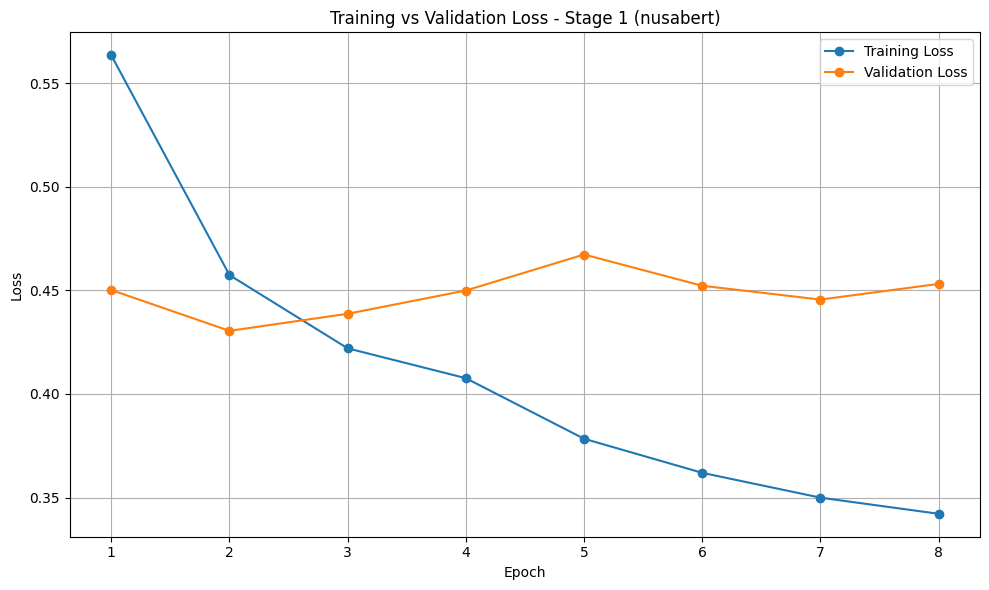

In [36]:
history_s1 = trainer_s1.state.log_history

# Training loss rata-rata per epoch
train_logs_s1 = [x for x in history_s1 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s1 = [x['epoch'] for x in train_logs_s1]
train_losses_s1 = [x['loss'] for x in train_logs_s1]

epoch_numbers_s1 = sorted(set(int(np.ceil(e)) for e in train_epochs_s1))
avg_train_loss_s1 = [
    np.mean([l for e, l in zip(train_epochs_s1, train_losses_s1) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s1
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s1 = {}
for x in history_s1:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s1:
            val_loss_by_epoch_s1[ep] = x['eval_loss']
val_epochs_s1 = sorted(val_loss_by_epoch_s1)
val_losses_s1 = [val_loss_by_epoch_s1[ep] for ep in val_epochs_s1]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s1, avg_train_loss_s1, marker='o', label='Training Loss')
plt.plot(val_epochs_s1, val_losses_s1, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 1 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [37]:
pred1 = trainer_s1.predict(test_dataset_1)
pred_label1 = pred1.predictions.argmax(axis=1)

probs1_test = torch.softmax(torch.tensor(pred1.predictions), dim=-1)[:, 1].numpy()

print("Stage 1 classification report -- test set:")
print(classification_report(y_test, pred_label1))

Stage 1 classification report -- test set:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89      1440
           1       0.65      0.82      0.73       480

    accuracy                           0.85      1920
   macro avg       0.79      0.84      0.81      1920
weighted avg       0.86      0.85      0.85      1920



In [38]:
cm_s1 = confusion_matrix(y_test, pred_label1, labels=[0, 1])

cm_df_s1 = pd.DataFrame(
    cm_s1,
    index=["Actual Non-Toxic (0)", "Actual Toxic (1)"],
    columns=["Predicted Non-Toxic (0)", "Predicted Toxic (1)"]
)

cm_df_s1

,Predicted Non-Toxic (0),Predicted Toxic (1)
Actual Non-Toxic (0),1231,209
Actual Toxic (1),86,394


In [39]:
print(f"ROC-AUC (test): {roc_auc_score(y_test, probs1_test):.4f}")
print(f"PR-AUC  (test): {average_precision_score(y_test, probs1_test):.4f}\n")

ROC-AUC (test): 0.9107
PR-AUC  (test): 0.7747



In [40]:
# import shutil

# shutil.make_archive(
#     "/content/best_s1_optuna",
#     "zip",
#     root_dir="/content",
#     base_dir="best_s1_optuna"
# )

# print("ZIP berhasil dibuat: /content/best_s1_optuna.zip")

# Stage 2

In [41]:
df_toxic = df_main[df_main["toxicity"] == 1].copy()

In [42]:
# This variant keeps ALL 5 labels.
LABEL_COLS = [
    "insults",
    "identity_attack",
    "threat_incitement_to_violence",
    "profanity_obscenity",
    "sexually_explicit",
]

x2 = df_toxic["processed_text"]
y2 = df_toxic[LABEL_COLS]

In [43]:
# Padanan stratify=y di Stage 1 untuk multilabel: iterative stratification menjaga
# proporsi tiap label (termasuk label langka) tetap mirip di train/val/test.
def ml_train_test_split(x, y, test_size, random_state=42):
    msss = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=test_size, random_state=random_state)
    train_idx, test_idx = next(msss.split(x, y.values))
    return x.iloc[train_idx], x.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]

x2_train_full, x2_test, y2_train_full, y2_test = ml_train_test_split(x2, y2, test_size=0.2, random_state=42)
x2_train, x2_val, y2_train, y2_val = ml_train_test_split(x2_train_full, y2_train_full, test_size=0.125, random_state=42)

print("Stage 2 split sizes:", {"train": len(x2_train), "val": len(x2_val), "test": len(x2_test)})
print(pd.DataFrame({"train": y2_train.sum(), "val": y2_val.sum(), "test": y2_test.sum()}))

Stage 2 split sizes: {'train': 1679, 'val': 240, 'test': 480}
                               train  val  test
insults                          738  106   211
identity_attack                  696   99   199
threat_incitement_to_violence     75   11    22
profanity_obscenity              251   36    72
sexually_explicit                 43    6    12


In [44]:
# Random oversampling of minority-label rows for Stage 2 (multi-label). For each label
# whose positive count is below the most frequent label's count, duplicate (with
# replacement) rows carrying that label until the gap is filled. Only the TRAIN split is
# resampled -- val/test keep their natural distribution.
def oversample_multilabel(df, label_cols, random_state=42):
    max_count = df[label_cols].sum().max()
    parts = [df]
    for col in label_cols:
        col_count = df[col].sum()
        n_needed = int(max_count - col_count)
        if n_needed > 0:
            minority_rows = df[df[col] == 1]
            if len(minority_rows) > 0:
                parts.append(minority_rows.sample(n=n_needed, replace=True, random_state=random_state))
    balanced = pd.concat(parts).sample(frac=1, random_state=random_state).reset_index(drop=True)
    return balanced

In [45]:
# Oversample the TRAIN split only. val/test keep their natural distribution.
train_df_s2 = pd.concat([x2_train, y2_train], axis=1)
print("Before oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})
train_df_s2 = oversample_multilabel(train_df_s2, LABEL_COLS, random_state=42)
print("After oversampling:", {c: int(train_df_s2[c].sum()) for c in LABEL_COLS})

x2_train, y2_train = train_df_s2["processed_text"], train_df_s2[LABEL_COLS]

Before oversampling: {'insults': 738, 'identity_attack': 696, 'threat_incitement_to_violence': 75, 'profanity_obscenity': 251, 'sexually_explicit': 43}
After oversampling: {'insults': 1074, 'identity_attack': 1145, 'threat_incitement_to_violence': 747, 'profanity_obscenity': 977, 'sexually_explicit': 759}


In [46]:
import pandas as pd
from datasets import Dataset, DatasetDict

def make_df_s2(x, y):
    if isinstance(x, pd.Series):
        x = x.to_frame()

    df = x.copy()
    df["label"] = y.astype(float).values.tolist()
    return df.reset_index(drop=True)

train_df_s2 = make_df_s2(x2_train, y2_train)
val_df_s2 = make_df_s2(x2_val, y2_val)
test_df_s2 = make_df_s2(x2_test, y2_test)

dataset_s2 = DatasetDict({
    "train": Dataset.from_pandas(train_df_s2),
    "validation": Dataset.from_pandas(val_df_s2),
    "test": Dataset.from_pandas(test_df_s2),
})

print(dataset_s2)

DatasetDict({
    train: Dataset({
        features: ['processed_text', 'label'],
        num_rows: 3566
    })
    validation: Dataset({
        features: ['processed_text', 'label'],
        num_rows: 240
    })
    test: Dataset({
        features: ['processed_text', 'label'],
        num_rows: 480
    })
})


In [47]:
tokenizer_s2 = AutoTokenizer.from_pretrained("indolem/indobertweet-base-uncased")

In [48]:
def tokenize_s2(batch):
    return tokenizer_s2(batch["processed_text"], truncation=True, max_length=128, padding="max_length")

tokenized_datasets_2 = dataset_s2.map(tokenize_s2, batched=True)

tokenized_datasets_2 = tokenized_datasets_2.remove_columns(["processed_text"])
tokenized_datasets_2 = tokenized_datasets_2.rename_column("label", "labels")
tokenized_datasets_2.set_format("torch")

train_dataset_2 = tokenized_datasets_2["train"]
val_dataset_2 = tokenized_datasets_2["validation"]
test_dataset_2 = tokenized_datasets_2["test"]

print(tokenizer_s2.decode(train_dataset_2[0]["input_ids"], skip_special_tokens=True))
print(train_dataset_2[0]["labels"])

isu prabowo cekik wamentan, gerindra ungkap nasdem penyebar awalnya. rabu siang tante lina, mata najwa, t, malang, terbuka. mba nana, ganjar paling solutif. indomy for yoongi. kirgistan, jurnalis, bacapres bicara gagasan hugo, samir, tka china, felix, who, in riize
tensor([0., 1., 0., 0., 0.])


In [49]:
def safe_auc(score_fn, labels, probs):
    """AUC macro; NaN kalau ada label yang di split ini cuma punya satu kelas."""
    try:
        return score_fn(labels, probs, average="macro")
    except ValueError:
        return float("nan")


def compute_metrics_s2(eval_pred):
    logits, labels = eval_pred
    probs = 1 / (1 + np.exp(-logits))   # sigmoid per label
    preds = (probs >= 0.5).astype(int)
    return {
        "accuracy": accuracy_score(labels, preds),   # exact match (subset accuracy)
        "precision_micro": precision_score(labels, preds, average="micro", zero_division=0),
        "recall_micro": recall_score(labels, preds, average="micro", zero_division=0),
        "f1_micro": f1_score(labels, preds, average="micro", zero_division=0),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "roc_auc": safe_auc(roc_auc_score, labels, probs),
        "pr_auc": safe_auc(average_precision_score, labels, probs),
    }

In [50]:
MODEL_NAME = "indolem/indobertweet-base-uncased"
STUDY_NAME_S2 = "stage2_oversampling_s2_v2"   # nama baru: split berbeda dari v1
N_TRIALS_S2 = 10
OUTPUT_ROOT_S2 = "./optuna_s2"
FINAL_DIR_S2 = "./best_s2_optuna"
SEED = 42
LOGGING_STEPS = 10
METRIC_S2 = "f1_macro"   # macro: setiap label (termasuk yang langka) berbobot sama

In [51]:
# search space
def suggest_params_s2(trial):
    """Nama key = nama parameter Optuna, jadi study.best_params bisa langsung dipakai ulang."""
    return {
        # Prioritas tinggi
        "learning_rate": trial.suggest_float("learning_rate", 8e-6, 6e-5, log=True),
        "warmup_ratio": trial.suggest_float("warmup_ratio", 0.0, 0.2),
        "batch_size": trial.suggest_categorical("batch_size", [8, 16, 32]),
        "num_train_epochs": trial.suggest_int("num_train_epochs", 3, 8),
        "class_weight_alpha": trial.suggest_float("class_weight_alpha", 0.3, 1.0),
        # Prioritas menengah
        "dropout": trial.suggest_float("dropout", 0.1, 0.3),
        "lr_scheduler_type": trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        # Prioritas rendah
        "weight_decay": trial.suggest_float("weight_decay", 0.0, 0.1),
        "n_frozen_layers": trial.suggest_int("n_frozen_layers", 0, 6),
        "freeze_embeddings": trial.suggest_categorical("freeze_embeddings", [False, True]),
    }

In [52]:
def freeze_layer(model, n_freeze, freeze_emb):
    """Bekukan embeddings (opsional) + n_freeze layer encoder."""
    base = model.base_model   # .bert untuk BERT, .roberta untuk XLM-R, dst.
    if freeze_emb:
        for p in base.embeddings.parameters():
            p.requires_grad = False
    for layer in base.encoder.layer[:n_freeze]:
        for p in layer.parameters():
            p.requires_grad = False


class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial, metric="eval_f1"):
        self.trial = trial
        self.metric = metric

    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        if not metrics or self.metric not in metrics:
            return
        self.trial.report(metrics[self.metric], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def build_trainer_s2(params, out_dir, trial=None):
    """Dipakai oleh objective DAN final training, jadi setup-nya pasti identik."""
    # set_seed mengunci random, numpy, dan torch -> inisialisasi classifier reproducible
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(LABEL_COLS),
        problem_type="multi_label_classification",
        id2label={i: l for i, l in enumerate(LABEL_COLS)},
        label2id={l: i for i, l in enumerate(LABEL_COLS)},
        hidden_dropout_prob=params["dropout"],
        attention_probs_dropout_prob=params["dropout"],
    )
    freeze_layer(model, params["n_frozen_layers"], params["freeze_embeddings"])

    # Warmup dihitung manual dari jumlah step total
    n_gpu = max(1, torch.cuda.device_count())
    steps_per_epoch = math.ceil(len(train_dataset_2) / (params["batch_size"] * n_gpu))
    warmup_steps = int(params["warmup_ratio"] * steps_per_epoch * params["num_train_epochs"])

    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=params["num_train_epochs"],
        per_device_train_batch_size=params["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=params["learning_rate"],
        warmup_steps=warmup_steps,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        save_only_model=True,
        save_total_limit=1,
        metric_for_best_model=METRIC_S2,
        greater_is_better=True,
        fp16=torch.cuda.is_available(),
        logging_steps=LOGGING_STEPS,
        disable_tqdm=False,          # progress bar per step + tabel metrik per epoch
        report_to=[],
        seed=SEED,
    )

    callbacks = [EarlyStoppingCallback(early_stopping_patience=2)]
    if trial is not None:
        callbacks.append(OptunaPruningCallback(trial, metric=f"eval_{METRIC_S2}"))

    # Trainer biasa: problem_type multi_label -> BCEWithLogitsLoss tanpa weighting,
    # imbalance ditangani oleh oversampling saja.
    return Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset_2,
        eval_dataset=val_dataset_2,
        compute_metrics=compute_metrics_s2,
        callbacks=callbacks,
    )


In [53]:
def objective_s2(trial):
    params = suggest_params_s2(trial)
    out_dir = f"{OUTPUT_ROOT_S2}/trial_{trial.number}"

    print(f"\n{'=' * 70}\nTrial {trial.number}")
    for k, v in params.items():
        print(f"  {k:20s}: {v:.2e}" if isinstance(v, float) and v < 1e-3 else f"  {k:20s}: {v}")

    trainer = None
    try:
        trainer = build_trainer_s2(params, out_dir, trial)
        trainer.train()
        print(f"Trial {trial.number} selesai | best val {METRIC_S2} = {trainer.state.best_metric:.4f}")
        return trainer.state.best_metric
    except torch.cuda.OutOfMemoryError:
        print(f"Trial {trial.number}: GPU out of memory, dilewati")
        raise optuna.TrialPruned("GPU out of memory")
    finally:
        del trainer
        gc.collect()
        torch.cuda.empty_cache()
        shutil.rmtree(out_dir, ignore_errors=True)

In [54]:
study_s2 = optuna.create_study(
    direction="maximize",
    study_name=STUDY_NAME_S2,
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=2),  # jangan prune di epoch awal, F1 masih dipengaruhi warmup
    storage="sqlite:///optuna_s2.db",    # file terpisah dari stage 1
    load_if_exists=True,
)

# Kalau session terputus, rerun sel ini hanya menjalankan sisa trial sampai total N_TRIALS_S2
done = sum(t.state.is_finished() for t in study_s2.trials)
remaining = max(0, N_TRIALS_S2 - done)
print(f"Trial selesai: {done} | sisa: {remaining}")
study_s2.optimize(objective_s2, n_trials=remaining, gc_after_trial=True)

Trial selesai: 0 | sisa: 10

Trial 0
  learning_rate       : 1.70e-05
  warmup_ratio        : 0.19014286128198324
  batch_size          : 8
  num_train_epochs    : 3
  class_weight_alpha  : 0.3406585285177396
  dropout             : 0.273235229154987
  lr_scheduler_type   : cosine
  weight_decay        : 0.0020584494295802446
  n_frozen_layers     : 6
  freeze_embeddings   : False


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.935874,0.833793,0.258333,0.615385,0.217054,0.320917,0.356457,0.767640,0.510585
2,0.770078,0.799463,0.291667,0.569892,0.410853,0.477477,0.493182,0.799168,0.584657
3,0.745710,0.789258,0.320833,0.564516,0.542636,0.553360,0.555858,0.802348,0.600273


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Trial 0 selesai | best val f1_macro = 0.5559

Trial 1
  learning_rate       : 1.15e-05
  warmup_ratio        : 0.03668090197068676
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.7282970263056656
  dropout             : 0.12789877213040837
  lr_scheduler_type   : cosine
  weight_decay        : 0.0456069984217036
  n_frozen_layers     : 5
  freeze_embeddings   : True


...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Trial 8 selesai | best val f1_macro = 0.5781

Trial 9
  learning_rate       : 4.16e-05
  warmup_ratio        : 0.1721461166512687
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.38390575713357794
  dropout             : 0.1675230342807256
  lr_scheduler_type   : linear
  weight_decay        : 0.05187906217433661
  n_frozen_layers     : 4
  freeze_embeddings   : True


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.745501,0.750819,0.341667,0.582278,0.534884,0.557576,0.550561,0.793252,0.597386
2,0.492738,0.710252,0.354167,0.616114,0.503876,0.554371,0.541118,0.810247,0.623368


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



In [55]:
print(f"Best trial #{study_s2.best_trial.number} | val {METRIC_S2} = {study_s2.best_value:.4f}")
for k, v in study_s2.best_params.items():
    print(f"  {k:20s}: {v}")

trials_df_s2 = study_s2.trials_dataframe(attrs=("number", "value", "state", "params"))
trials_df_s2.columns = [c.replace("params_", "") for c in trials_df_s2.columns]
display(trials_df_s2.sort_values("value", ascending=False).head(10)
        .round({"value": 4, "dropout": 4, "warmup_ratio": 4, "weight_decay": 4})
        .style.format({"learning_rate": "{:.2e}"}))

Best trial #8 | val f1_macro = 0.5781
  learning_rate       : 5.207537298482086e-05
  warmup_ratio        : 0.1616240759128834
  batch_size          : 16
  num_train_epochs    : 4
  class_weight_alpha  : 0.9247912989429843
  dropout             : 0.20786844838313012
  lr_scheduler_type   : cosine
  weight_decay        : 0.03180034749718639
  n_frozen_layers     : 0
  freeze_embeddings   : True


,number,value,state,batch_size,class_weight_alpha,dropout,freeze_embeddings,learning_rate,lr_scheduler_type,n_frozen_layers,num_train_epochs,warmup_ratio,weight_decay
8,8,0.578100,COMPLETE,16,0.924791,0.207900,True,5.21e-05,cosine,0,4,0.161600,0.031800
2,2,0.575600,COMPLETE,8,0.975942,0.261700,True,2.64e-05,linear,3,8,0.009300,0.068400
5,5,0.573500,COMPLETE,16,0.839889,0.114800,False,3.79e-05,linear,4,7,0.039700,0.086300
0,0,0.555900,COMPLETE,8,0.340659,0.273200,False,1.70e-05,cosine,6,3,0.190100,0.002100
9,9,0.553500,PRUNED,16,0.383906,0.167500,True,4.16e-05,linear,4,4,0.172100,0.051900
3,3,0.530900,COMPLETE,16,0.682697,0.137000,True,8.57e-06,linear,6,6,0.181900,0.093900
1,1,0.522000,COMPLETE,16,0.728297,0.127900,True,1.15e-05,cosine,5,4,0.036700,0.045600
7,7,0.414300,PRUNED,16,0.935297,0.149900,False,8.42e-06,cosine,0,6,0.021600,0.022900
4,4,0.313700,COMPLETE,32,0.880116,0.171400,True,9.56e-06,cosine,5,4,0.039200,0.014100
6,6,0.255000,PRUNED,32,0.383716,0.242600,False,1.50e-05,linear,3,5,0.065000,0.077100


In [56]:
optuna.visualization.plot_param_importances(study_s2).show()
optuna.visualization.plot_optimization_history(study_s2).show()

In [57]:
trainer_s2 = build_trainer_s2(study_s2.best_params, FINAL_DIR_S2)
trainer_s2.train()
model_s2 = trainer_s2.model

trainer_s2.save_model(FINAL_DIR_S2)
tokenizer_s2.save_pretrained(FINAL_DIR_S2)
print(f"Final model tersimpan di {FINAL_DIR_S2}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Epoch,Training Loss,Validation Loss,Accuracy,Precision Micro,Recall Micro,F1 Micro,F1 Macro,Roc Auc,Pr Auc
1,0.785623,0.819075,0.308333,0.496644,0.573643,0.532374,0.486816,0.785488,0.565219
2,0.566290,0.734833,0.320833,0.567568,0.406977,0.474041,0.478915,0.812261,0.623342
3,0.472205,0.727714,0.366667,0.584459,0.670543,0.624549,0.578126,0.801379,0.594151
4,0.406643,0.750814,0.366667,0.553517,0.701550,0.618803,0.574580,0.798981,0.598463


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Final model tersimpan di ./best_s2_optuna


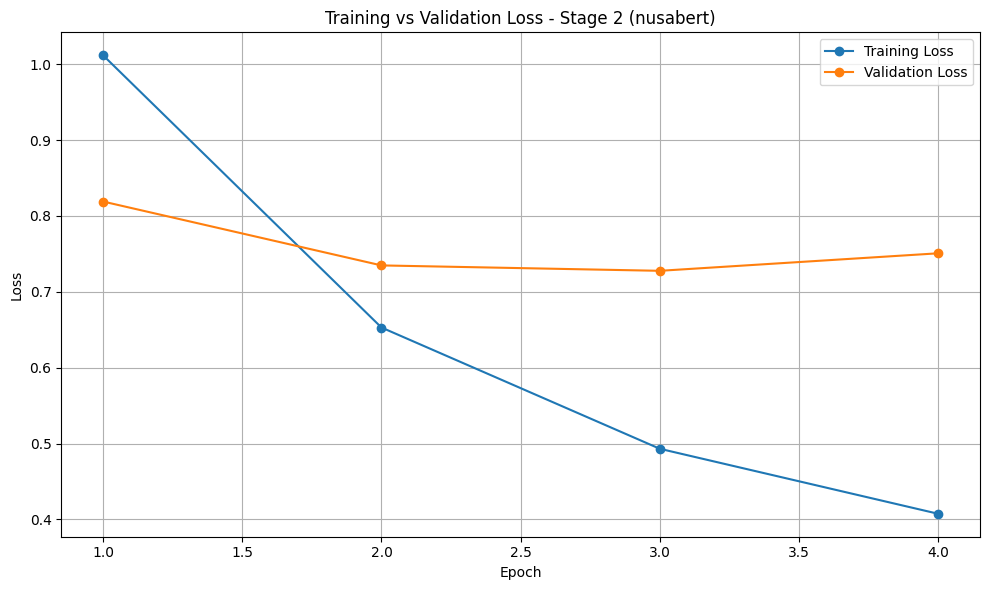

In [58]:
history_s2 = trainer_s2.state.log_history

# Training loss rata-rata per epoch
train_logs_s2 = [x for x in history_s2 if 'loss' in x and 'eval_loss' not in x]
train_epochs_s2 = [x['epoch'] for x in train_logs_s2]
train_losses_s2 = [x['loss'] for x in train_logs_s2]

epoch_numbers_s2 = sorted(set(int(np.ceil(e)) for e in train_epochs_s2))
avg_train_loss_s2 = [
    np.mean([l for e, l in zip(train_epochs_s2, train_losses_s2) if int(np.ceil(e)) == ep])
    for ep in epoch_numbers_s2
]

# Validation loss per epoch (ambil yang pertama tiap epoch)
val_loss_by_epoch_s2 = {}
for x in history_s2:
    if 'eval_loss' in x:
        ep = int(round(x['epoch']))
        if ep > 0 and ep not in val_loss_by_epoch_s2:
            val_loss_by_epoch_s2[ep] = x['eval_loss']
val_epochs_s2 = sorted(val_loss_by_epoch_s2)
val_losses_s2 = [val_loss_by_epoch_s2[ep] for ep in val_epochs_s2]

plt.figure(figsize=(10, 6))
plt.plot(epoch_numbers_s2, avg_train_loss_s2, marker='o', label='Training Loss')
plt.plot(val_epochs_s2, val_losses_s2, marker='o', label='Validation Loss')
plt.title('Training vs Validation Loss - Stage 2 (nusabert)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [59]:
pred2 = trainer_s2.predict(test_dataset_2)
probs2_test = 1 / (1 + np.exp(-pred2.predictions))   # sigmoid per label
y2_true = pred2.label_ids.astype(int)

pred_label2 = (probs2_test >= 0.5).astype(int)

print("Stage 2 classification report -- test set:")
print(classification_report(y2_true, pred_label2, target_names=LABEL_COLS, zero_division=0))

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning:

Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.



Stage 2 classification report -- test set:
                               precision    recall  f1-score   support

                      insults       0.59      0.69      0.64       211
              identity_attack       0.54      0.58      0.56       199
threat_incitement_to_violence       0.37      0.32      0.34        22
          profanity_obscenity       0.53      0.72      0.61        72
            sexually_explicit       0.57      0.33      0.42        12

                    micro avg       0.55      0.63      0.59       516
                    macro avg       0.52      0.53      0.51       516
                 weighted avg       0.55      0.63      0.59       516
                  samples avg       0.51      0.53      0.49       516



In [60]:
cm_results = []

for i, label in enumerate(LABEL_COLS):
    tn, fp, fn, tp = confusion_matrix(
        y2_true[:, i],
        pred_label2[:, i],
        labels=[0, 1]
    ).ravel()
    cm_results.append({"Label": label, "TN": tn, "FP": fp, "FN": fn, "TP": tp})

cm_s2 = pd.DataFrame(cm_results)
cm_s2

,Label,TN,FP,FN,TP
0,insults,167,102,65,146
1,identity_attack,183,98,84,115
2,threat_incitement_to_violence,446,12,15,7
3,profanity_obscenity,362,46,20,52
4,sexually_explicit,465,3,8,4


In [62]:
import shutil

shutil.make_archive(
    "/kaggle/working/best_s1_optuna",
    "zip",
    root_dir="/kaggle/working",
    base_dir="best_s1_optuna"
)

print("ZIP berhasil dibuat: /kaggle/working/best_s1_optuna.zip")

ZIP berhasil dibuat: /kaggle/working/best_s1_optuna.zip


In [63]:
import shutil

shutil.make_archive(
    "/kaggle/working/best_s2_optuna",
    "zip",
    root_dir="/kaggle/working",
    base_dir="best_s2_optuna"
)

print("ZIP berhasil dibuat: /kaggle/working/best_s2_optuna.zip")

ZIP berhasil dibuat: /kaggle/working/best_s2_optuna.zip
